# Visual Diagnostics and Numerical Diagnostics

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html): Cheat sheet of helpful array & table methods used in Data 8!

**Recommended Readings**: 
- [Visual Diagnoistics](https://inferentialthinking.com/chapters/15/5/visual-diagnostics/)
- [Numerical Diagnoistics](https://inferentialthinking.com/chapters/15/6/numerical-diagnostics/)

In [155]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
from math import ceil

In [183]:
# function to calculate standard units
def standard_units(numbers_array):
    "Convert any array of numbers to standard units."
    return (numbers_array - np.mean(numbers_array))/np.std(numbers_array)

def correlation(table, label_x, label_y):
    return np.mean(standard_units(table.column(label_x))*standard_units(table.column(label_y)))

def slope(table, label_x, label_y):
    r = correlation(table, label_x, label_y)
    return r*np.std(table.column(label_y))/np.std(table.column(label_x))

def intercept(table, label_x, label_y):
    return np.mean(table.column(label_y)) - slope(table, label_x, label_y)*np.mean(table.column(label_x))
    
def fitted_values(table, x, y):
    """Return an array of the regression estimates (predictions) at all the x value."""
    a = slope(table, x, y)
    b = intercept(table, x, y)
    return a * table.column(x) + b

def residuals(table, x, y):
    predictions = fitted_values(table, x, y)
    return table.column(y) - predictions

### Residuals

Residuals are the vertical distances of the points from the regression line. There is one residual for each point in the scatter plot.

residual = observed value − regression estimate

residual = y − fitted value of y

residual = y − height of regression line at x

<img src="rmse-a.png" alt="root mean square error" width=400/>

The vertical red lines from the points to the regression line are residual.


### Regression Diagnostics

Residual plots help us make visual assessments of the quality of a linear regression analysis. Such assessments are called diagnostics. 

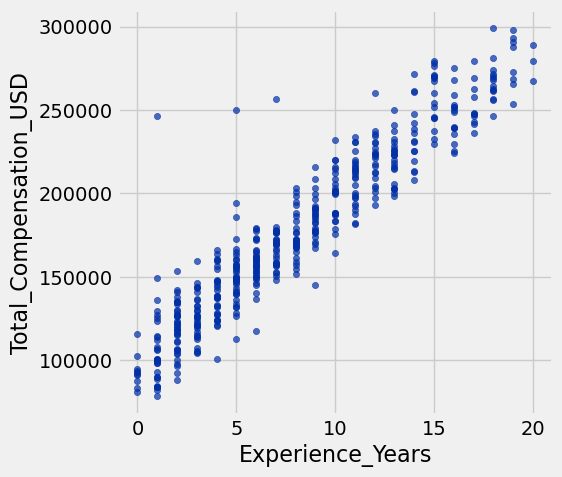

In [157]:
salaries = Table.read_table('experience_vs_compensation.csv').drop('Engineer_ID')
# remove the oulliers
salaries = salaries.where('Total_Compensation_USD', are.below(300001))
salaries.scatter('Experience_Years', 'Total_Compensation_USD')

In [158]:
correlation(salaries, 'Experience_Years', 'Total_Compensation_USD')

0.94238259835118754

In [159]:
salaries = salaries.with_columns(
        'Fitted Value', fitted_value(salaries, 'Experience_Years', 'Total_Compensation_USD'),
        'Residual', residuals(salaries, 'Experience_Years', 'Total_Compensation_USD')
    )
salaries

Experience_Years,Total_Compensation_USD,Fitted Value,Residual
6,162126,157861,4265.16
18,299142,271785,27357.1
11,218756,205329,13426.8
9,176846,186342,-9495.84
3,115023,129380,-14356.8
3,135878,129380,6498.17
1,89696,110392,-20696.5
14,260471,233810,26660.8
9,203191,186342,16849.2
11,197462,205329,-7867.18


In [160]:
def scatter_fit(table, x, y):
    table.scatter(x, y, s=15)
    plots.plot(table.column(x), fitted_values(table, x, y), lw=4, color='gold')
    plots.xlabel(x)
    plots.ylabel(y)

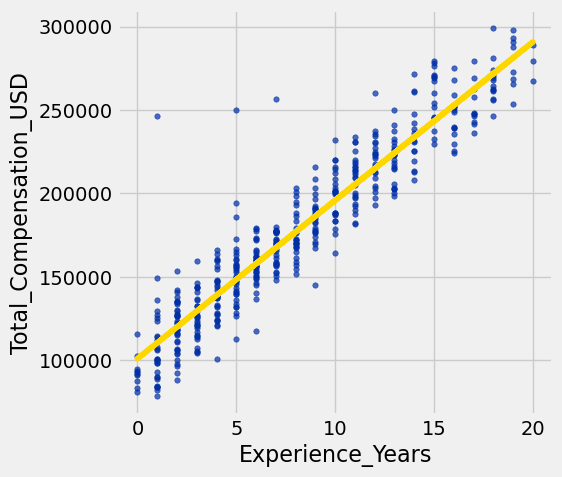

In [161]:
scatter_fit(salaries, 'Experience_Years', 'Total_Compensation_USD')

In [237]:
def residual_plot(table, x, y):
    x_array = table.column(x)
    t = Table().with_columns(
            x, x_array,
            'residuals', residuals(table, x, y)
        )
    t.scatter(x, 'residuals', color='r')
    xlims = make_array(min(x_array), max(x_array))
    plots.plot(xlims, make_array(0, 0), color='darkblue', lw=4)
    plots.title('Residual Plot')

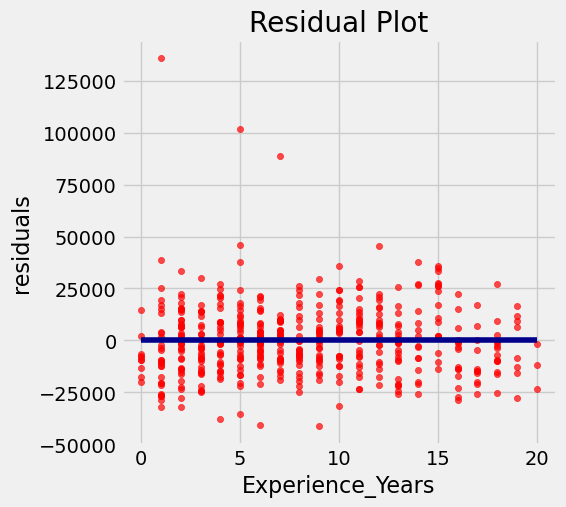

In [238]:
residual_plot(salaries, 'Experience_Years', 'Total_Compensation_USD')

In [239]:
# correlation between the predictor x and the residuals is very close to Zerols
round(correlation(salaries, 'Experience_Years', 'Residual'), 4)

0.0

The accuracy of the regression appears to be about the same across the observed range of the predictor variable.

Other than a few outliers, the plot isn’t narrower in some places and wider in others.

**"The residual plot of a good regression shows no pattern. The residuals look about the same, above and below the horizontal line at 0, across the range of the predictor variable."**

### Detecting Nonlinearity - trend to have a curve shape

#### Example 1

In [267]:
cars = Table().read_table('Cars2015_v1.csv')
#cars.show(3)

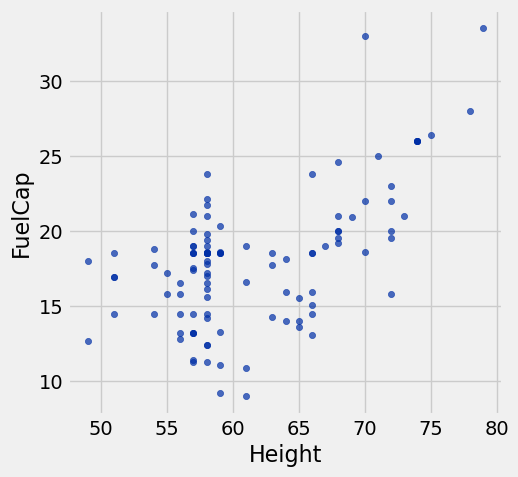

In [268]:
cars.scatter('Height', 'FuelCap') 

In [269]:
correlation(cars, 'Height', 'FuelCap')

0.575958949157927

In [270]:
cars_tmp = cars.select('Height', 'FuelCap').with_columns(
        'Fitted Value', fitted_value(cars, 'Height', 'FuelCap'),
        'Residual', residuals(cars, 'Height', 'FuelCap')
    )
cars_tmp.show(3)

Height,FuelCap,Fitted Value,Residual
61,9,17.8415,-8.84149
57,11.4,16.3151,-4.91506
57,11.3,16.3151,-5.01506


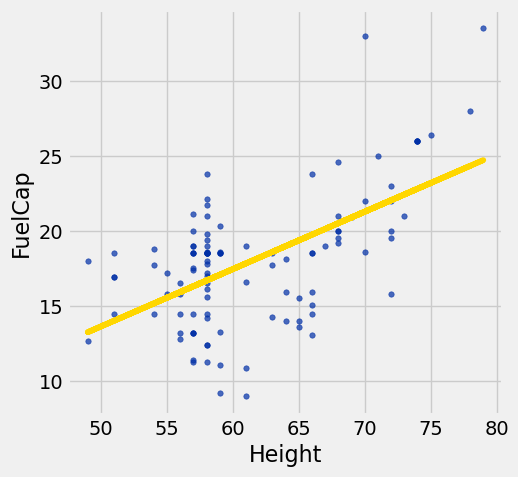

In [271]:
scatter_fit(cars_tmp, 'Height', 'FuelCap')

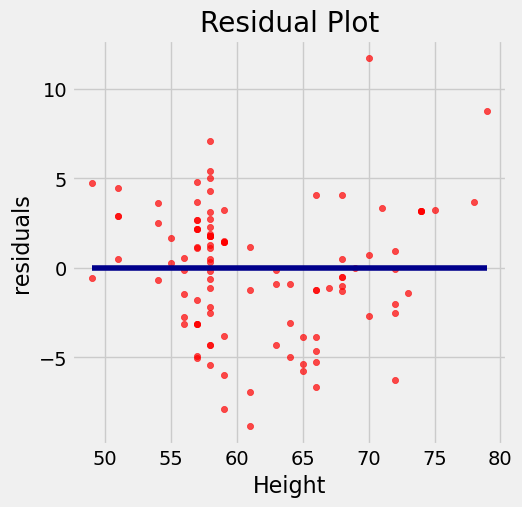

In [272]:
residual_plot(cars_tmp, 'Height', 'FuelCap')

In [273]:
# correlation between the predictor x and the residuals is very close to Zero
round(correlation(cars_tmp, 'Height', 'Residual'), 4)

-0.0

#### Example

In [247]:
dugong = Table.read_table('dugong.csv')
dugong

Length,Age
1.8,1
1.85,1.5
1.87,1.5
1.77,1.5
2.02,2.5
2.27,4
2.15,5
2.26,5
2.35,7
2.47,8


In [248]:
correlation(dugong, 'Length', 'Age')

0.82964745549057139

In [249]:
dugong = dugong.with_columns(
        'Fitted Value', fitted_value(dugong, 'Length', 'Age'),
        'Residual', residuals(dugong, 'Length', 'Age')
    )
dugong.show(3)

Length,Age,Fitted Value,Residual
1.8,1,-1.77781,2.77781
1.85,1.5,-0.589222,2.08922
1.87,1.5,-0.113788,1.61379


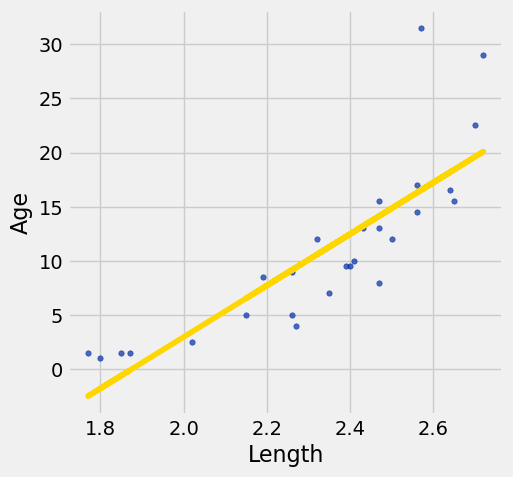

In [250]:
scatter_fit(dugong, 'Length', 'Age')

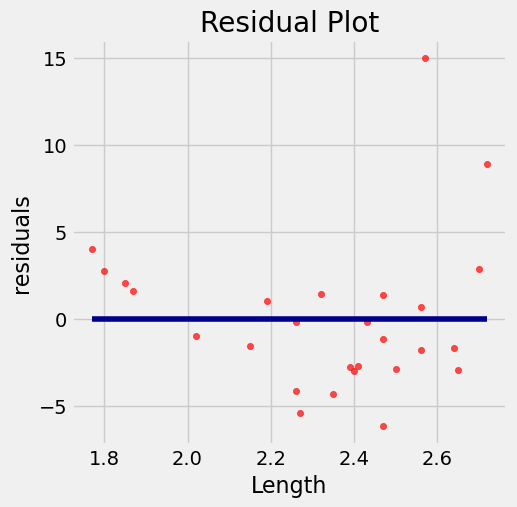

In [251]:
residual_plot(dugong, 'Length', 'Age')

In [266]:
# correlation between the predictor x and the residuals is very close to Zero
round(correlation(dugong, 'Length', 'Residual'), 4)

0.0

**"When a residual plot shows a pattern, there may be a non-linear relation between the variables."**

### Detecting Heteroscedasticity

Heteroscedasticity in data science means "“uneven spread”.

#### Example 1

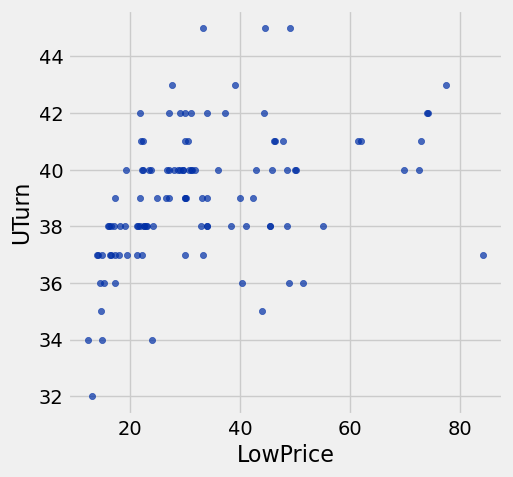

In [253]:
cars.scatter('LowPrice', 'UTurn')

In [254]:
correlation(cars, 'LowPrice', 'UTurn')

0.39591367485086459

In [255]:
cars_tmp = cars.select('LowPrice', 'UTurn').with_columns(
        'Fitted Value', fitted_value(cars, 'LowPrice', 'UTurn'),
        'Residual', residuals(cars, 'LowPrice', 'UTurn')
    )
cars_tmp.show(3)

LowPrice,UTurn,Fitted Value,Residual
12.27,34,37.8712,-3.87123
14.745,37,38.0149,-1.01492
13.99,37,37.9711,-0.971087


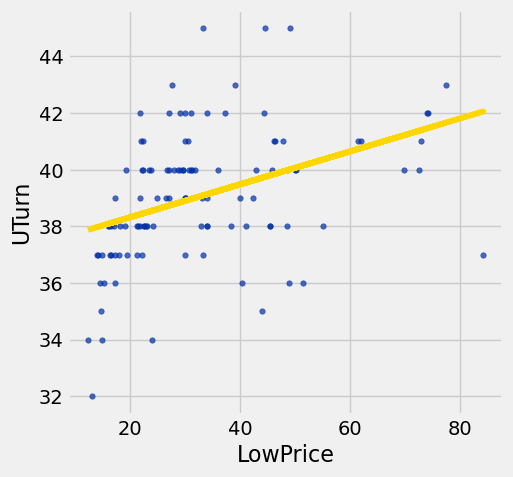

In [256]:
scatter_fit(cars_tmp, 'LowPrice', 'UTurn')

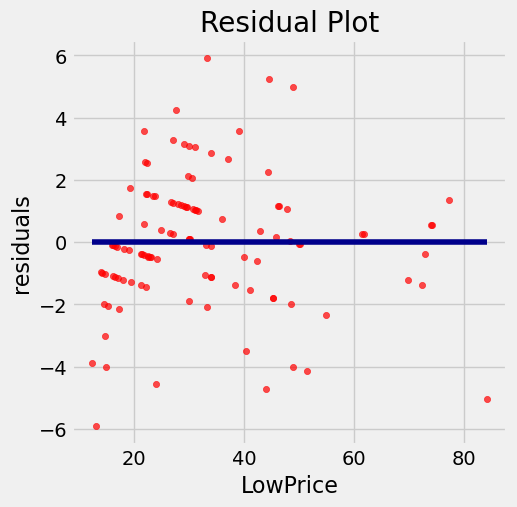

In [257]:
residual_plot(cars_tmp, 'LowPrice', 'UTurn')

In [258]:
# correlation between the predictor x and the residuals is very close to Zero
round(correlation(cars_tmp, 'LowPrice', 'Residual'), 4)

0.0

#### Example 2

In [259]:
hybrid = Table.read_table('hybrid.csv')
hybrid.show(3)

vehicle,year,msrp,acceleration,mpg,class
Prius (1st Gen),1997,24509.7,7.46,41.26,Compact
Tino,2000,35355,8.2,54.1,Compact
Prius (2nd Gen),2000,26832.2,7.97,45.23,Compact


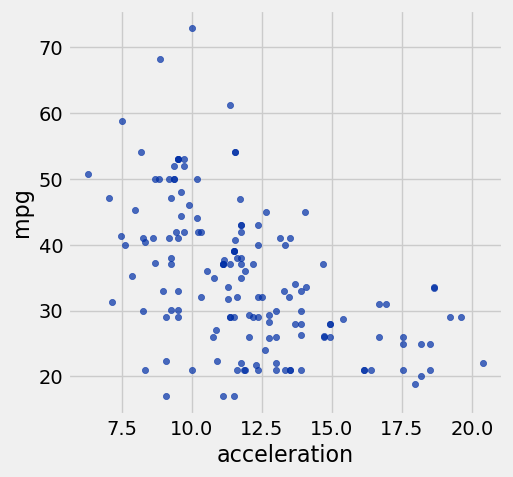

In [260]:
hybrid.scatter('acceleration', 'mpg')

In [261]:
correlation(hybrid, 'acceleration', 'mpg')

-0.5060703843771186

In [262]:
hybrid_tmp = hybrid.select('acceleration', 'mpg').with_columns(
        'Fitted Value', fitted_value(hybrid, 'acceleration', 'mpg'),
        'Residual', residuals(hybrid, 'acceleration', 'mpg')
    )
hybrid_tmp.show(3)

acceleration,mpg,Fitted Value,Residual
7.46,41.26,43.2933,-2.03325
8.2,54.1,41.8957,12.2043
7.97,45.23,42.3301,2.89993


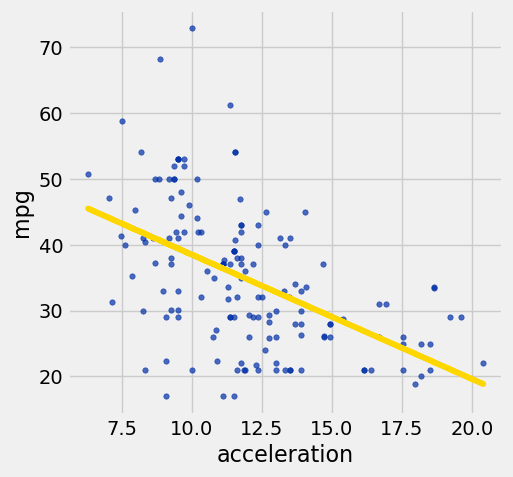

In [263]:
scatter_fit(hybrid_tmp, 'acceleration', 'mpg')

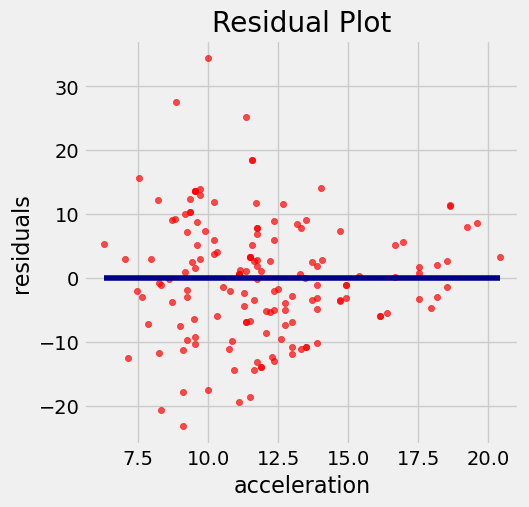

In [264]:
residual_plot(hybrid_tmp, 'acceleration', 'mpg')

In [265]:
# correlation between the predictor x and the residuals is very close to Zero
round(correlation(hybrid_tmp, 'acceleration', 'Residual'), 4)

-0.0

**"If the residual plot shows uneven variation about the horizontal line at 0, the regression estimates are not equally accurate across the range of the predictor variable."**